In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold, GridSearchCV,train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest
from sklearn.decomposition import PCA
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, classification_report,make_scorer
from sklearn import preprocessing
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import scipy.stats
import seaborn as sns
from re import match
#import optuna
import math
import shap
import sklearn


# Barabasi-Albert

In [ ]:
#Data handling

path = '/your/path'
data = pd.read_csv(path + 'pca_ba.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
y = subpop_data['sampling_method']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2112)

In [10]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [13]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [14]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [15]:
#Testing
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=y.unique()))

                      precision    recall  f1-score   support

            snowball       0.45      0.53      0.49       892
                 RWS       0.90      0.93      0.91       903
                IRWS       0.92      0.90      0.91       903
          traceroute       0.74      0.84      0.78       895
                MHRW       0.49      0.33      0.40       895
forest_fire_sampling       1.00      1.00      1.00       892
   frontier_sampling       1.00      1.00      1.00       920

            accuracy                           0.79      6300
           macro avg       0.79      0.79      0.78      6300
        weighted avg       0.79      0.79      0.79      6300



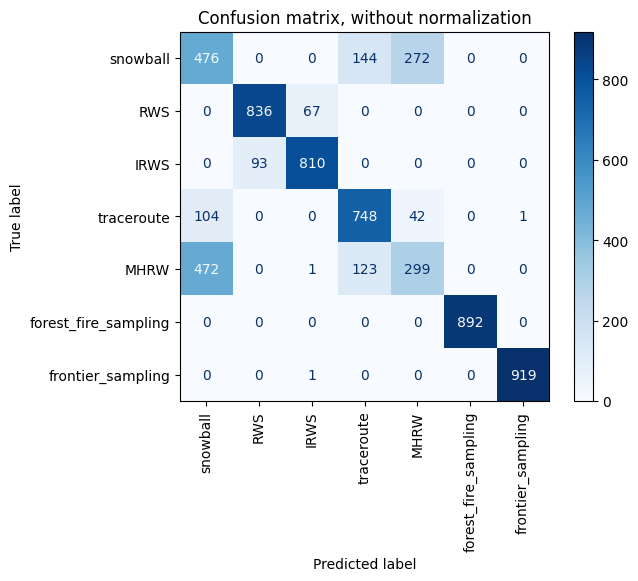

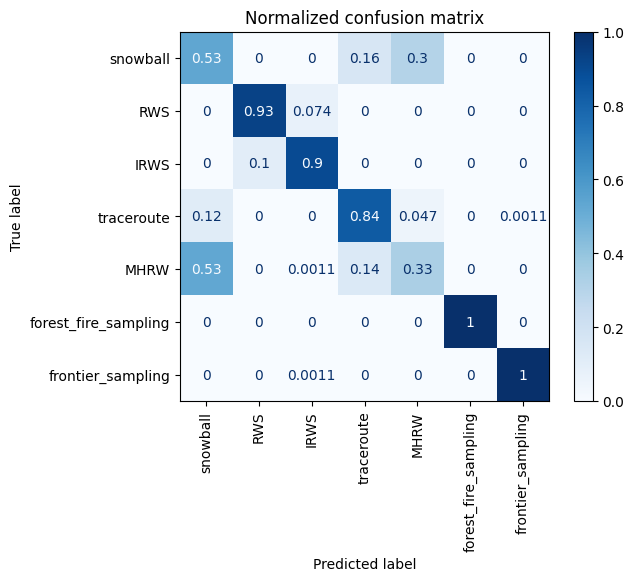

In [16]:
#Plot confusion matrixes
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", "true"),
]
for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=list(y.unique()),
        cmap=plt.cm.Blues,
        normalize=normalize,
    )
    disp.ax_.set_title(title)
    plt.xticks(rotation=90)
plt.show()

In [17]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [18]:
#Rename columns for better readability
X.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)

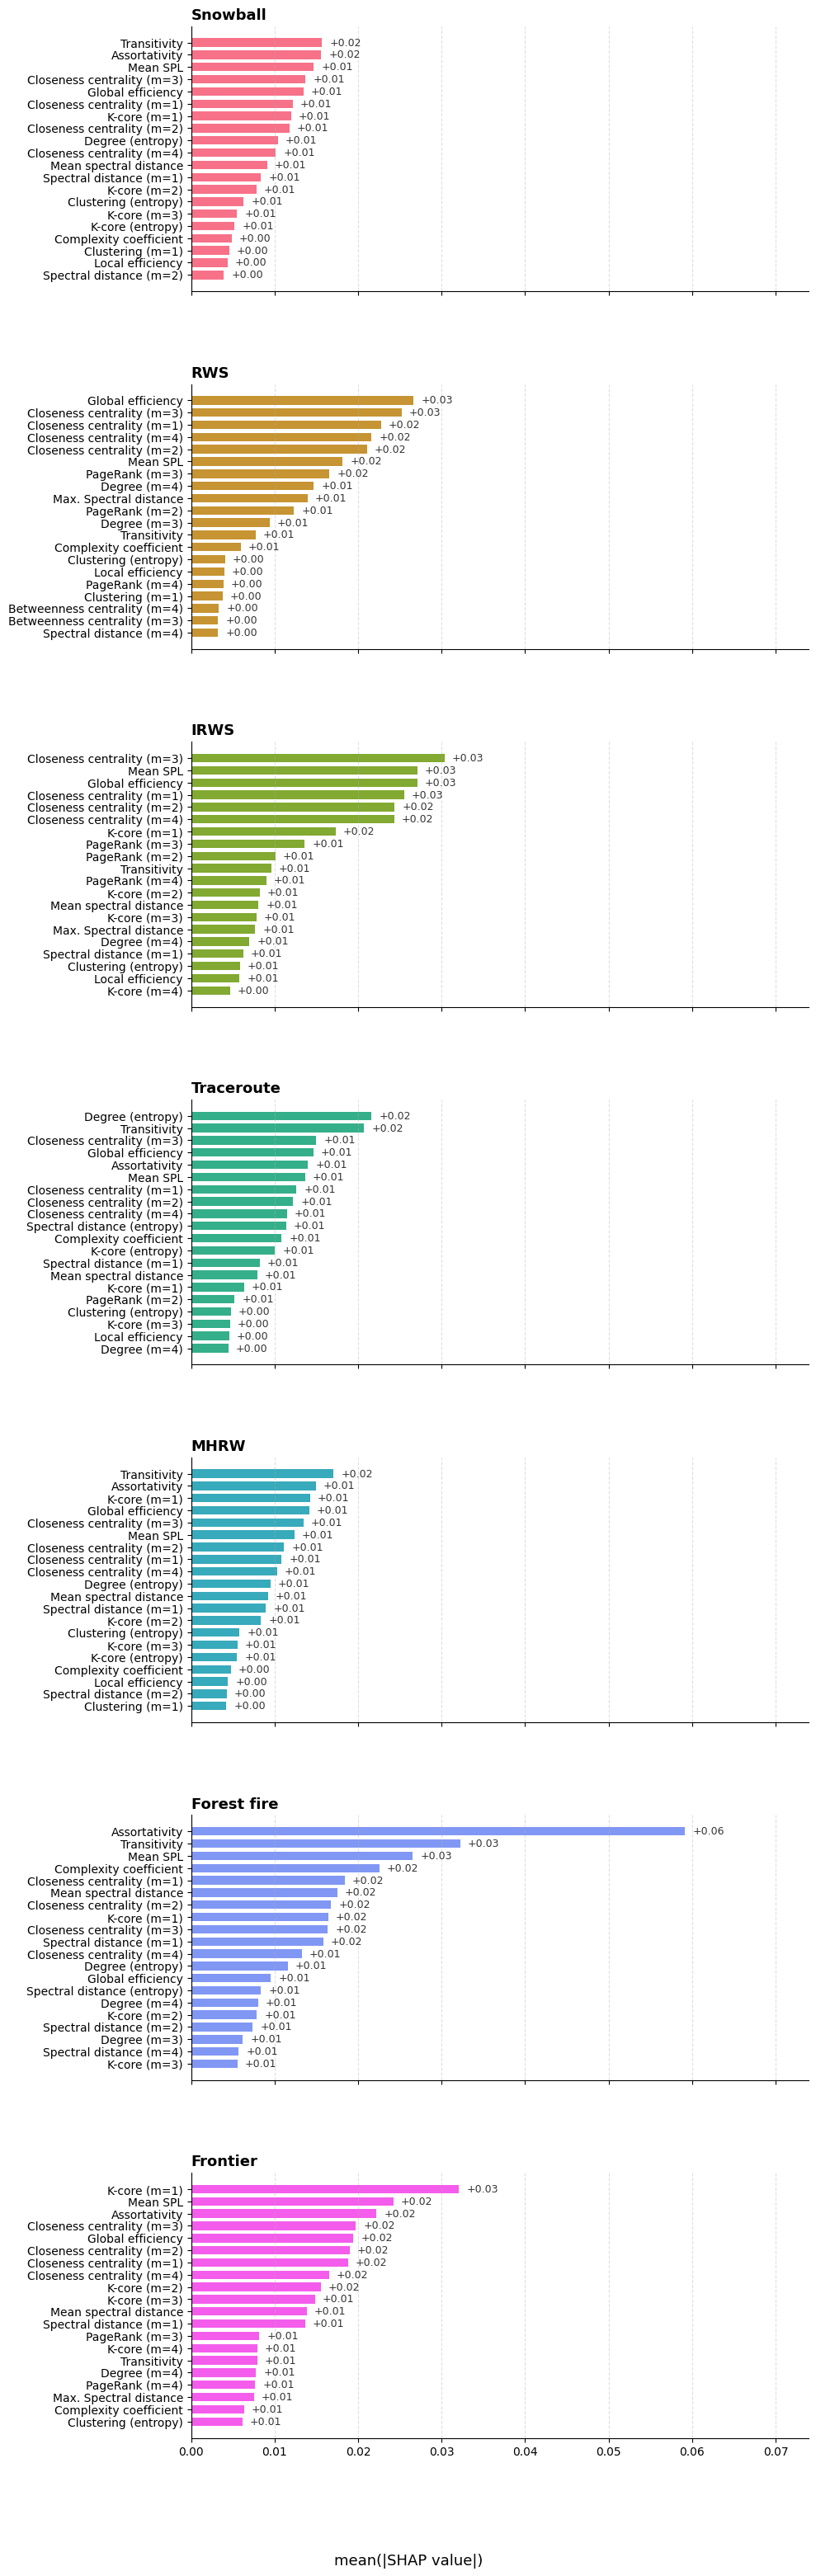

In [19]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['Snowball','RWS','IRWS','Traceroute','MHRW','Forest fire','Frontier']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_ba.pdf', format='pdf')
plt.show()

# Erdos-Reyni

In [ ]:
#Data handling

path = '/your/path'
data = pd.read_csv(path + 'pca_er.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
y = subpop_data['sampling_method']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2112)

In [21]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [23]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [25]:
#Training the model (simple RFClassifier)
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [26]:
#Testing
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=y.unique()))

                      precision    recall  f1-score   support

            snowball       0.49      0.57      0.53       892
                 RWS       0.60      0.75      0.67       903
                IRWS       0.67      0.50      0.57       903
          traceroute       0.86      0.88      0.87       895
                MHRW       0.49      0.39      0.44       895
forest_fire_sampling       1.00      1.00      1.00       892
   frontier_sampling       0.99      1.00      1.00       920

            accuracy                           0.73      6300
           macro avg       0.73      0.73      0.72      6300
        weighted avg       0.73      0.73      0.72      6300



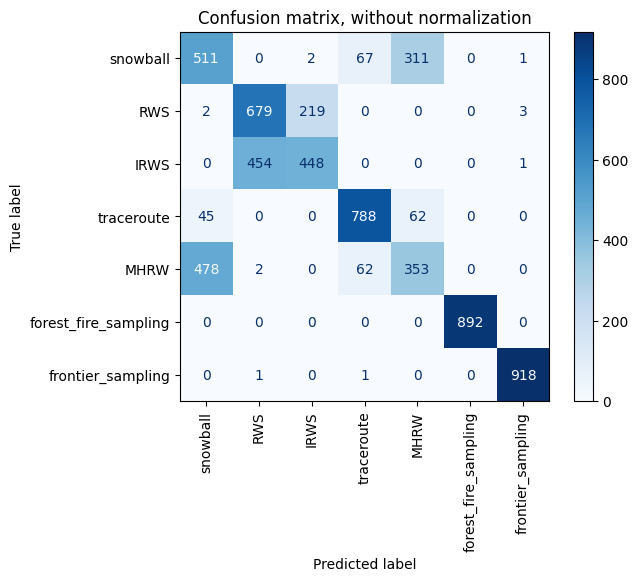

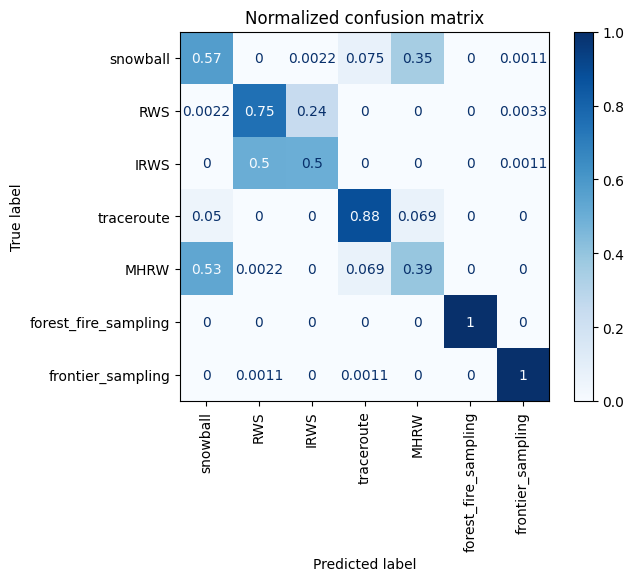

In [27]:
#Plot confusion matrixes
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", "true"),
]
for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=list(y.unique()),
        cmap=plt.cm.Blues,
        normalize=normalize,
    )
    disp.ax_.set_title(title)
    plt.xticks(rotation=90)
plt.show()

In [28]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [29]:
#Rename columns for better readability
X.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)

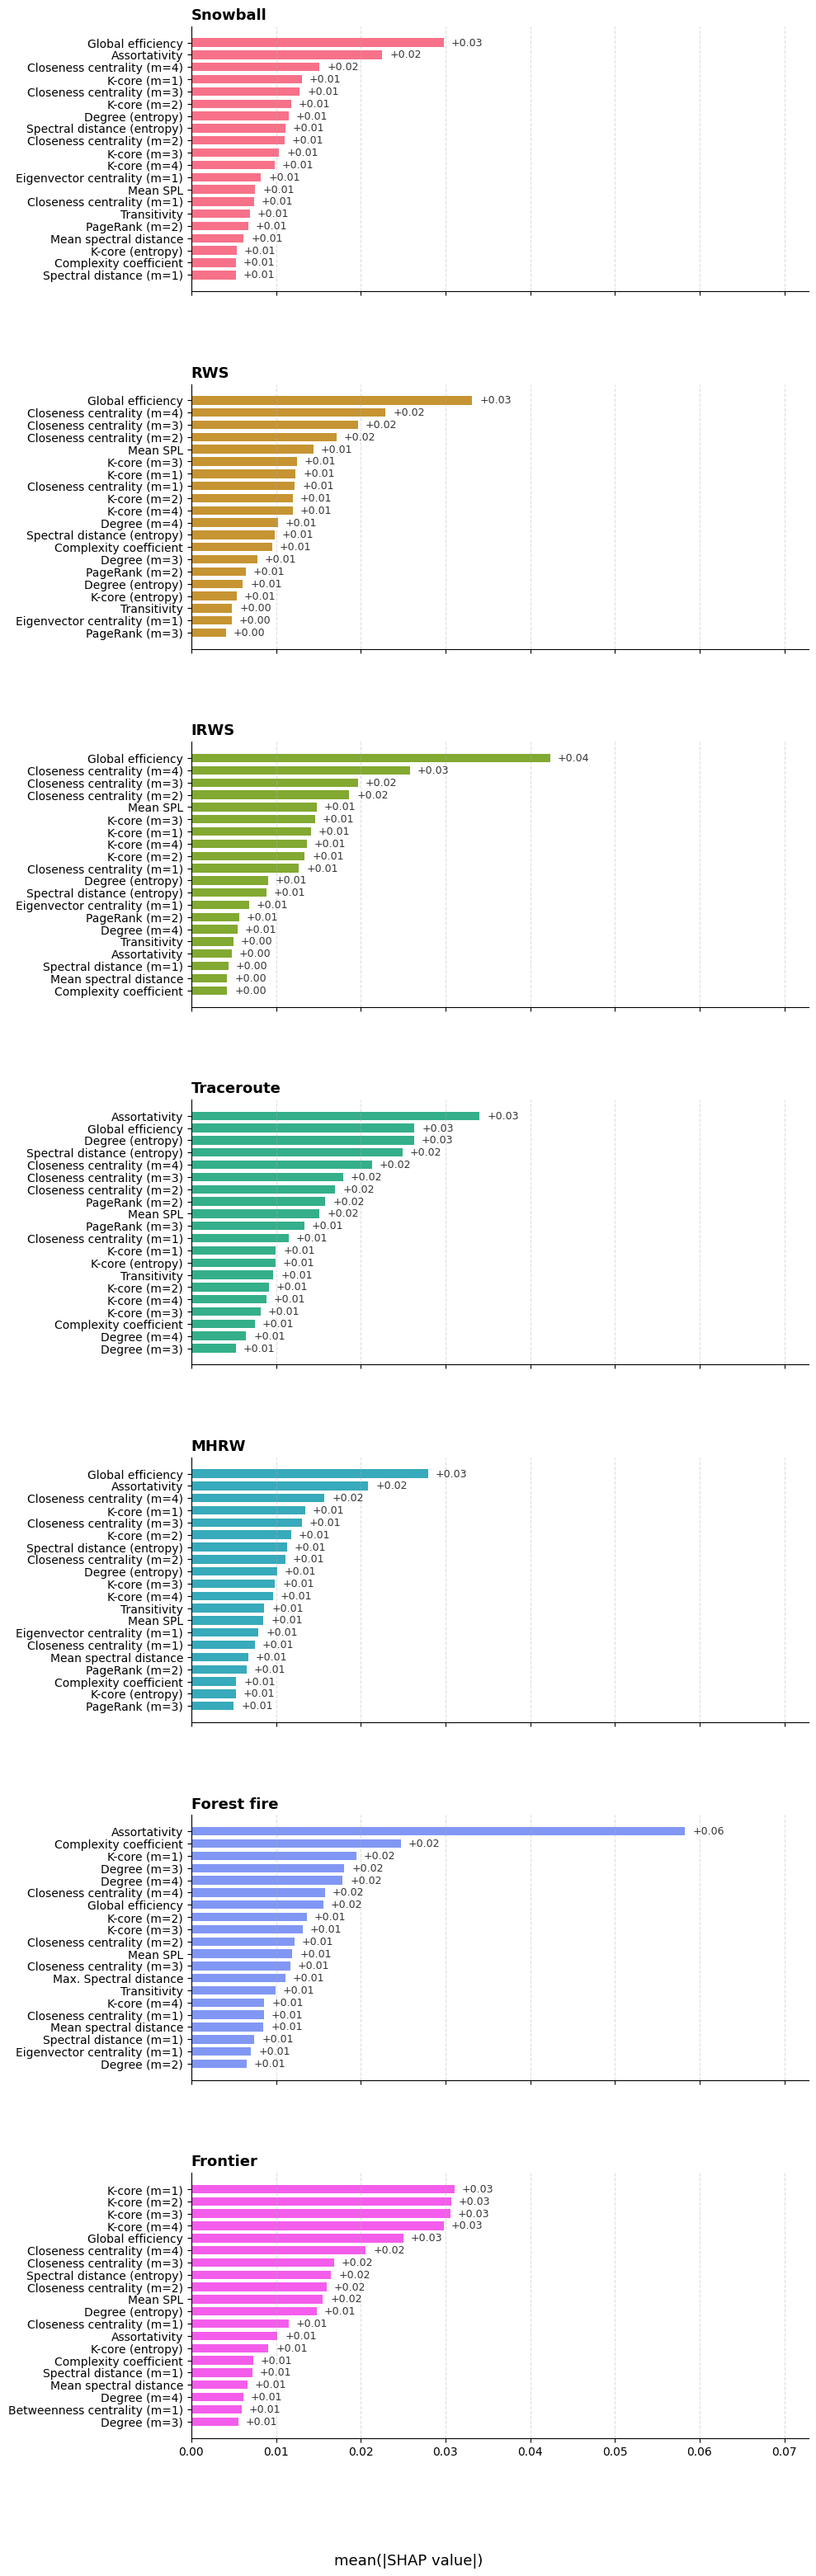

In [30]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['Snowball','RWS','IRWS','Traceroute','MHRW','Forest fire','Frontier']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_er.pdf', format='pdf')
plt.show()

# Non-linear Barabási-Albert

In [ ]:
#Data handling

path = '/your/path'
data = pd.read_csv(path + 'pca_nlba.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
y = subpop_data['sampling_method']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2112)

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [ ]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [3]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=100, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [4]:
#Testing
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=y.unique()))

                      precision    recall  f1-score   support

            snowball       0.47      0.54      0.50       892
                 RWS       0.99      1.00      1.00       903
                IRWS       1.00      0.99      1.00       903
          traceroute       0.93      0.95      0.94       895
                MHRW       0.46      0.39      0.42       895
forest_fire_sampling       0.99      0.96      0.98       892
   frontier_sampling       0.96      0.99      0.98       920

            accuracy                           0.83      6300
           macro avg       0.83      0.83      0.83      6300
        weighted avg       0.83      0.83      0.83      6300



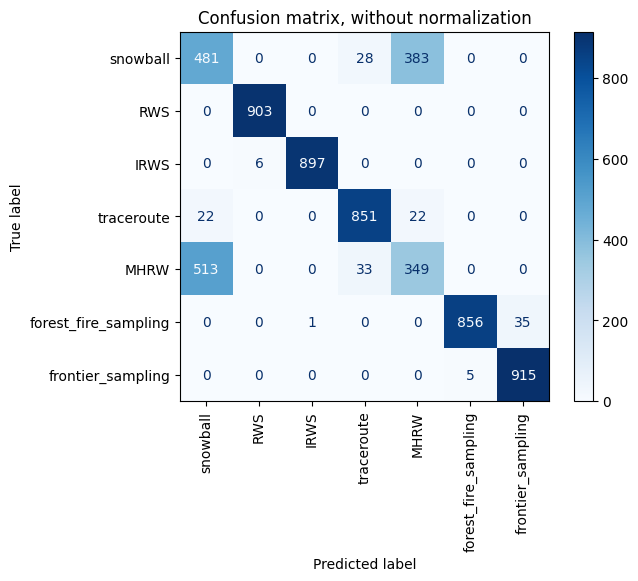

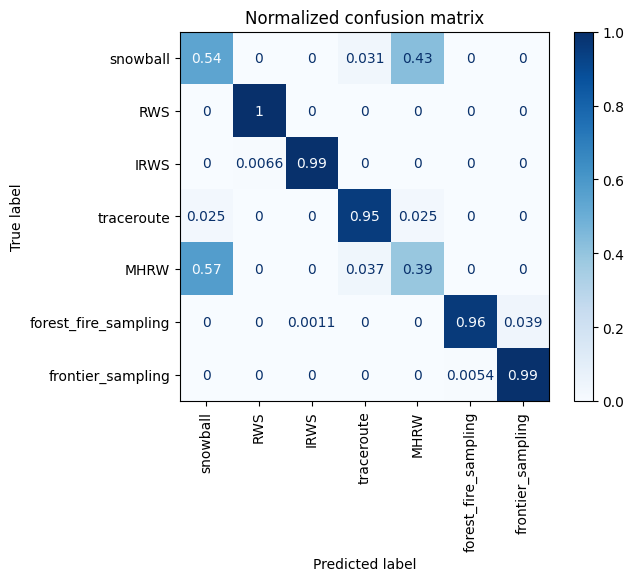

In [5]:
#Plot confusion matrixes
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", "true"),
]
for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=list(y.unique()),
        cmap=plt.cm.Blues,
        normalize=normalize,
    )
    disp.ax_.set_title(title)
    plt.xticks(rotation=90)
plt.show()

In [6]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [7]:
#Rename columns for better readability
X.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)

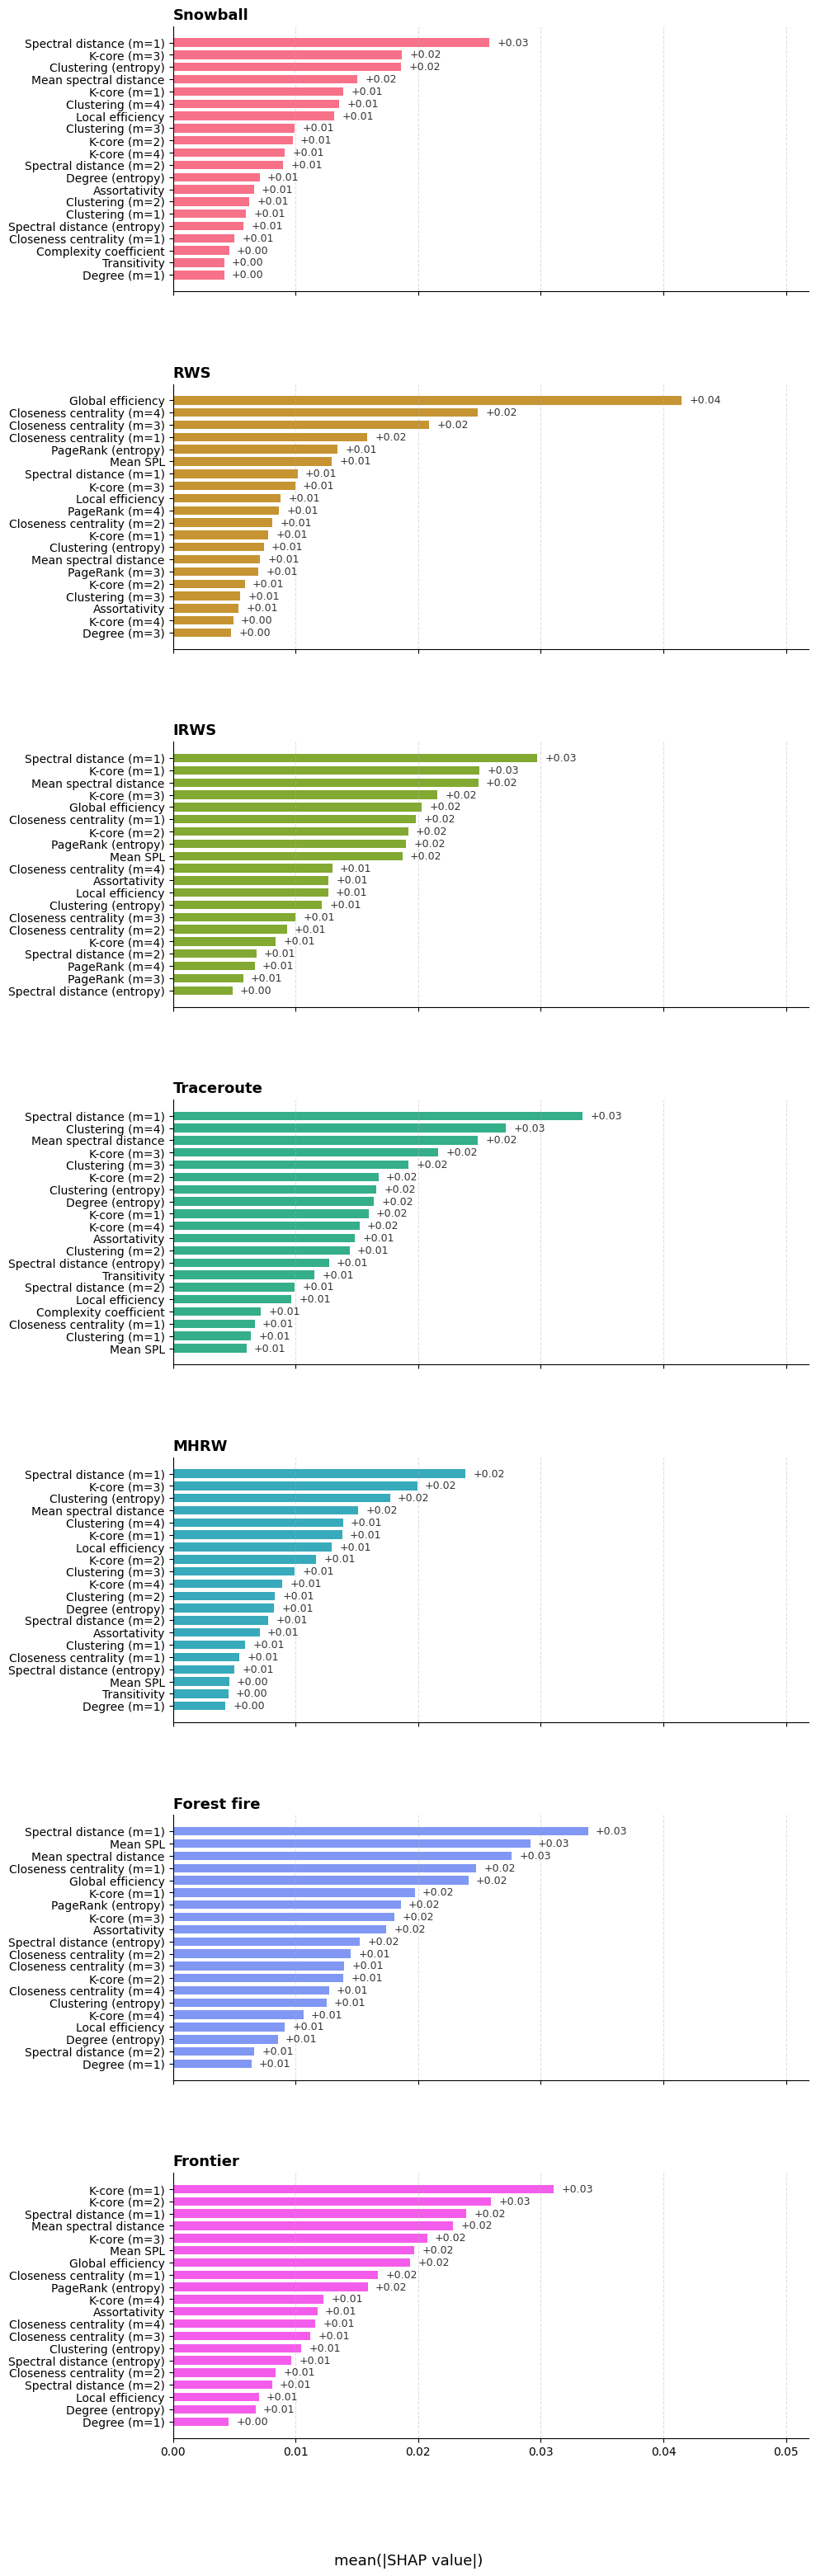

In [8]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['Snowball','RWS','IRWS','Traceroute','MHRW','Forest fire','Frontier']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_nlba.pdf', format='pdf')
plt.show()

# Watts-Strogatz

In [ ]:
#Data handling

path = '/your/path'
data = pd.read_csv(path + 'pca_ws.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
y = subpop_data['sampling_method']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2112)

In [35]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [33]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [37]:
#Training the model (simple RFClassifier)
model = RandomForestClassifier(n_estimators=300, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [38]:
#Testing
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=y.unique()))

                      precision    recall  f1-score   support

            snowball       0.41      0.38      0.40       892
                 RWS       0.48      0.46      0.47       903
                IRWS       0.50      0.51      0.51       903
          traceroute       0.62      0.82      0.70       895
                MHRW       0.43      0.33      0.37       895
forest_fire_sampling       0.99      1.00      0.99       892
   frontier_sampling       1.00      1.00      1.00       920

            accuracy                           0.64      6300
           macro avg       0.63      0.64      0.63      6300
        weighted avg       0.63      0.64      0.64      6300



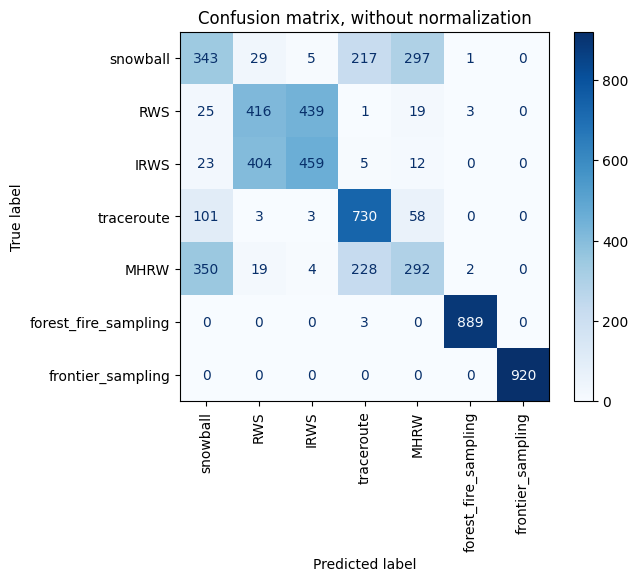

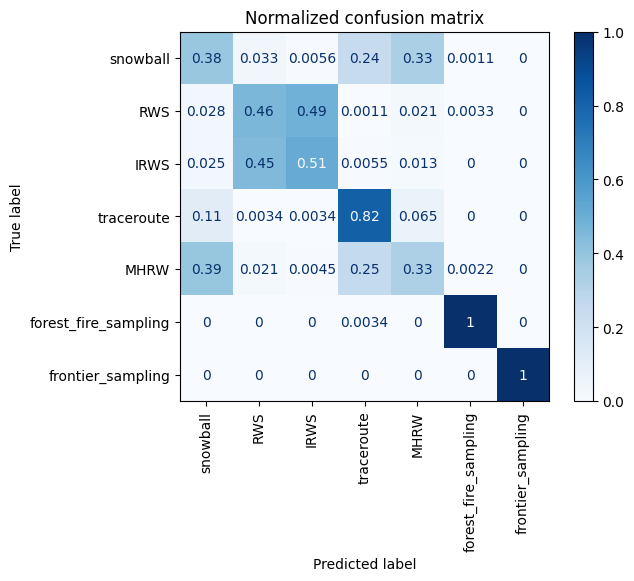

In [39]:
#Plot confusion matrixes
titles_options = [
    ("Confusion matrix, without normalization", None),
    ("Normalized confusion matrix", "true"),
]
for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=list(y.unique()),
        cmap=plt.cm.Blues,
        normalize=normalize,
    )
    disp.ax_.set_title(title)
    plt.xticks(rotation=90)
plt.show()

In [40]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [41]:
#Rename columns for better readability
X.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X)

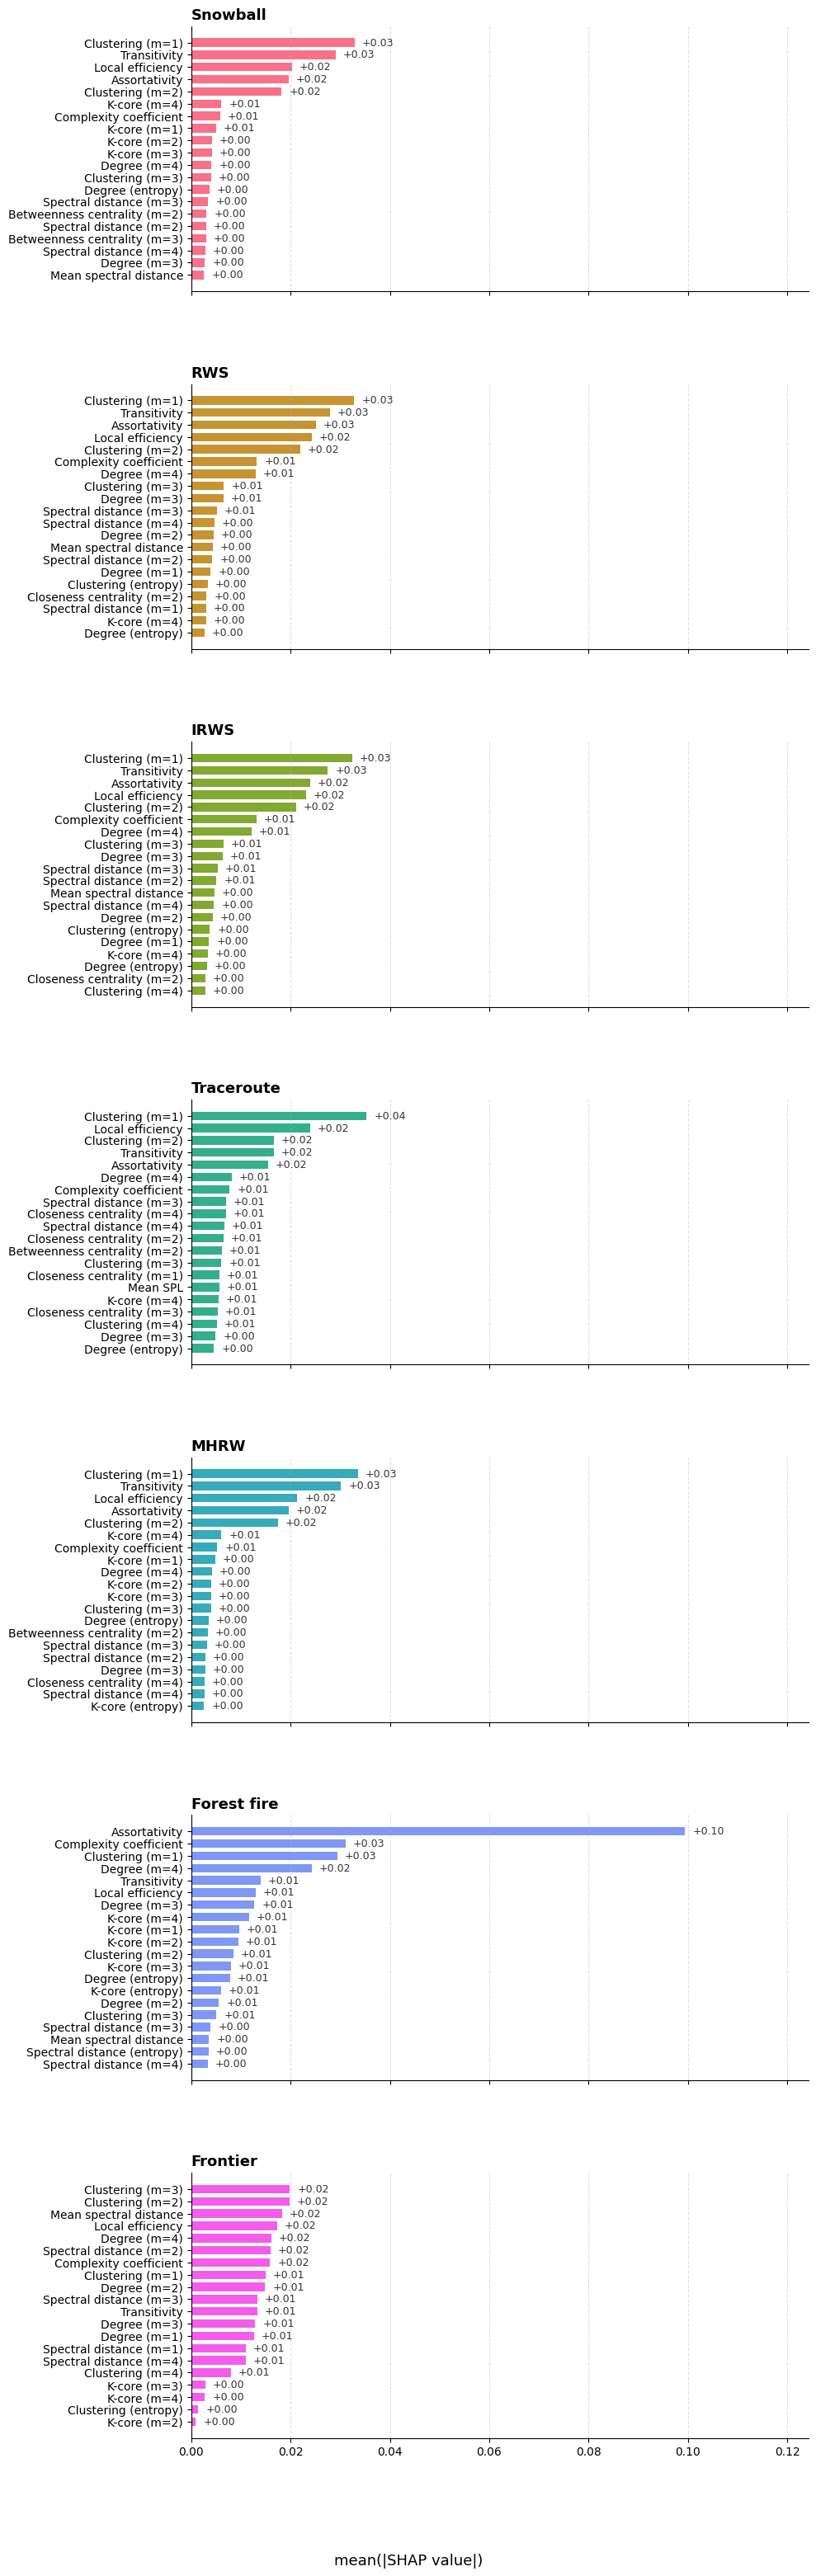

In [42]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['Snowball','RWS','IRWS','Traceroute','MHRW','Forest fire','Frontier']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_ws.pdf', format='pdf')
plt.show()